# Expérience 1 — Combien coûte la darija en tokens ?

**Question :** pour une même phrase, combien de tokens en plus la darija coûte-t-elle par rapport au français et à l'arabe standard, selon le tokenizer ?

**Métriques :**
- **fertilité** = nombre moyen de tokens par mot ;
- **ratio de parité** = tokens de la phrase en darija / tokens de la même phrase en français (Petrov et al., NeurIPS 2023) ;
- **taux d'octets** = part des tokens qui ne forment pas un caractère complet (lettre arabe coupée en octets) ou inconnus.

**Données :**
- **FLORES+** (dès maintenant) : français, arabe standard, darija marocaine, darija tunisienne. Pas d'algérien.
- **MADAR** (dès que l'accès est obtenu) : ajoute Alger, Rabat, Fès, Tunis, Sfax.

**Résultat (à remplir à la fin) :**

## 0. Mise en place

Sur Colab : *Exécution → Modifier le type d'exécution* n'est pas nécessaire, **le CPU suffit** pour cette expérience.


In [1]:
import os, sys

REPO = "Ninessss/darija-llm"
BRANCH = "exp1/cout-tokens"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import userdata
    if not os.path.exists("/content/darija-llm"):
        try:
            gh = userdata.get("GITHUB_TOKEN")
            url = f"https://{gh}@github.com/{REPO}.git"
        except Exception:
            url = f"https://github.com/{REPO}.git"
        !git clone -q -b {BRANCH} {url} /content/darija-llm
    %cd /content/darija-llm
    !pip install -q transformers tokenizers datasets sentencepiece protobuf pandas matplotlib
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Dossier de travail :", os.getcwd())

/content/darija-llm
Dossier de travail : /content/darija-llm


In [2]:
from huggingface_hub import login

try:
    token = userdata.get("HF_Token") if IN_COLAB else os.environ.get("HF_Token")
    login(token=token)
    print("Connecté à Hugging Face")
except Exception as e:
    print("Pas de token Hugging Face : Llama 3, Gemma et FLORES+ ne pourront pas être chargés.", e)

Pas de token Hugging Face : Llama 3, Gemma et FLORES+ ne pourront pas être chargés. Secret HF_Token does not exist.


## 1. Les tokenizers comparés

Les identifiants marqués `# à vérifier` sont ceux dont le nom exact sur Hugging Face doit être confirmé. Si un tokenizer ne se charge pas, la cellule l'indique et continue avec les autres.

In [3]:
from transformers import AutoTokenizer

TOKENIZER_IDS = {
    "GPT-2":      "gpt2",
    "Llama 3":    "meta-llama/Meta-Llama-3-8B",       # accès à demander
    "Qwen 2.5":   "Qwen/Qwen2.5-0.5B",
    "Gemma 2":    "google/gemma-2-2b",                # accès à demander
    "mBERT":      "bert-base-multilingual-cased",
    "DziriBERT":  "alger-ia/dziribert",               # à vérifier
    "DarijaBERT": "SI2M-Lab/DarijaBERT",              # à vérifier
    "TunBERT":    "tunis-ai/TunBERT",                 # à vérifier
}

tokenizers = {}
for name, hf_id in TOKENIZER_IDS.items():
    try:
        tokenizers[name] = AutoTokenizer.from_pretrained(hf_id)
        print(f"OK      {name:<11} {hf_id}  (vocabulaire : {len(tokenizers[name]):,})")
    except Exception as e:
        print(f"ÉCHEC   {name:<11} {hf_id}  -> {type(e).__name__}: {str(e)[:100]}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

OK      GPT-2       gpt2  (vocabulaire : 50,257)


... (34 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

OK      TunBERT     tunis-ai/TunBERT  (vocabulaire : 30,522)


## 2. Les phrases parallèles

FLORES+ contient les **mêmes phrases** traduites dans chaque langue, alignées par leur `id`. On garde le split `dev` (997 phrases) et `devtest` (1 012 phrases).

In [4]:
import pandas as pd
from datasets import load_dataset

FLORES_LANGS = {
    "Français":         "fra_Latn",
    "Arabe standard":   "arb_Arab",
    "Darija marocaine": "ary_Arab",
    "Darija tunisienne":"aeb_Arab",
}

def load_flores(code):
    parts = []
    for split in ["dev", "devtest"]:
        ds = load_dataset("openlanguagedata/flores_plus", code, split=split)
        parts.append(ds.to_pandas()[["id", "text"]].assign(split=split))
    return pd.concat(parts).set_index(["split", "id"])["text"]

flores = pd.DataFrame({lang: load_flores(code) for lang, code in FLORES_LANGS.items()}).dropna()
print(f"{len(flores)} phrases alignées dans les {flores.shape[1]} langues")
flores.head(3)

README.md:   0%|          | 0.00/75.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

fra_Latn.jsonl:   0%|          | 0.00/452k [00:00<?, ?B/s]

fra_Latn.jsonl:   0%|          | 0.00/472k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

... (25 outputs left out)

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

2009 phrases alignées dans les 4 langues


Français  \
split id                                                      
dev   0   Des scientifiques de l’école de médecine de l’...   
      1   Selon les chercheurs principaux, cela pourrait...   
      2   Le JAS 39C Gripen s’est écrasé sur une piste a...   

                                             Arabe standard  \
split id                                                      
dev   0   في يوم الاثنين، أعلن علماء من كلية الطب بجامعة...   
      1   يقول الباحثون الرئيسيون أن هذا قد يؤدي إلى الك...   
      2   تحطمت طائرة جاس-٣٩ غربين على مدرج في حوالي الس...   

                                           Darija marocaine  \
split id                                                      
dev   0   قالو شي علماء من كلية الطب فجامعة ستانفورد نها...   
      1   باحثين كبار تيقولو أن هادشي ممكن يؤدي للكشف ال...   
      2   تزادحات االطيارة جاس 39C غريبن مع واحد الطريق ...   

                                          Darija tunisienne  
split id                                                     
dev   0   يوم الاثنين، أعلن علماء من كلية الطب بجامعة ست...  
      1   يقول الباحثون الرئيسيون أنو هذا يمكن يوصّل للك...  
      2   تحطمت طائرة جاس-39 غربين على البيست مع ال9:30 ...

Les textes passent par la même normalisation que le reste du projet (URLs, étirements de lettres, variantes d'alef…), pour que les comparaisons portent sur le même texte.

> On peut aussi relancer l'expérience **sans normalisation** pour voir ce qu'elle change : mettez `NORMALIZE = False`.

In [5]:
from src.normalize import normalize

NORMALIZE = True
data = flores.map(normalize) if NORMALIZE else flores.copy()
data.head(3)

Français  \
split id                                                      
dev   0   des scientifiques de l’école de médecine de l’...   
      1   selon les chercheurs principaux, cela pourrait...   
      2   le jas 39c gripen s’est écrasé sur une piste a...   

                                             Arabe standard  \
split id                                                      
dev   0   في يوم الاثنين، اعلن علماء من كليه الطب بجامعه...   
      1   يقول الباحثون الرئيسيون ان هذا قد يؤدي الي الك...   
      2   تحطمت طائره جاس-٣٩ غربين علي مدرج في حوالي الس...   

                                           Darija marocaine  \
split id                                                      
dev   0   قالو شي علماء من كليه الطب فجامعه ستانفورد نها...   
      1   باحثين كبار تيقولو ان هادشي ممكن يؤدي للكشف ال...   
      2   تزادحات االطياره جاس 39C غريبن مع واحد الطريق ...   

                                          Darija tunisienne  
split id                                                     
dev   0   يوم الاثنين، اعلن علماء من كليه الطب بجامعه ست...  
      1   يقول الباحثون الرئيسيون انو هذا يمكن يوصل للكش...  
      2   تحطمت طائره جاس-39 غربين علي البيست مع ال9:30 ...

## 3. Les mesures

Pour chaque tokenizer et chaque langue :
- `tokens_total` : nombre total de tokens sur tout le corpus ;
- `fertilite` : tokens par mot ;
- `parite_vs_fr` : moyenne, phrase par phrase, de tokens(langue) / tokens(français) ;
- `parite_vs_msa` : la même chose par rapport à l'arabe standard ;
- `taux_octets` : part des tokens inconnus ou coupés en octets.

In [6]:
import numpy as np
from tqdm.auto import tqdm
from src.metrics import is_broken_token

def count_tokens(tok, texts):
    return np.array([len(tok.encode(t, add_special_tokens=False)) for t in texts])

rows = []
for tok_name, tok in tqdm(tokenizers.items()):
    counts = {lang: count_tokens(tok, data[lang]) for lang in data.columns}
    for lang in data.columns:
        texts = data[lang]
        n_words = texts.str.split().str.len().to_numpy()
        ids = [i for t in texts for i in tok.encode(t, add_special_tokens=False)]
        rows.append({
            "tokenizer": tok_name,
            "langue": lang,
            "tokens_total": int(counts[lang].sum()),
            "fertilite": counts[lang].sum() / n_words.sum(),
            "parite_vs_fr": float(np.mean(counts[lang] / np.maximum(counts["Français"], 1))),
            "parite_vs_msa": float(np.mean(counts[lang] / np.maximum(counts["Arabe standard"], 1))),
            "taux_octets": float(np.mean([is_broken_token(tok, i) for i in ids])),
        })

results = pd.DataFrame(rows)
os.makedirs("results/figures", exist_ok=True)
results.to_csv("results/exp1_flores.csv", index=False)
results.round(3)

  0%|          | 0/8 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


,tokenizer,langue,tokens_total,fertilite,parite_vs_fr,parite_vs_msa,taux_octets
0,GPT-2,Français,104925,2.109,1.000,0.489,0.019
1,GPT-2,Arabe standard,218804,5.699,2.106,1.000,0.440
2,GPT-2,Darija marocaine,215266,5.752,2.076,0.993,0.452
3,GPT-2,Darija tunisienne,212030,5.747,2.042,0.972,0.446
4,Llama 3,Français,83675,1.682,1.000,0.969,0.000
5,Llama 3,Arabe standard,87946,2.291,1.061,1.000,0.000
6,Llama 3,Darija marocaine,91797,2.453,1.109,1.054,0.000
7,Llama 3,Darija tunisienne,87983,2.385,1.061,1.003,0.000
8,Qwen 2.5,Français,83769,1.683,1.000,0.950,0.000
9,Qwen 2.5,Arabe standard,90036,2.345,1.085,1.000,0.003


In [7]:
# Le tableau principal : ratio de parité par rapport au français
parite = results.pivot(index="tokenizer", columns="langue", values="parite_vs_fr")[list(FLORES_LANGS)]
parite = parite.sort_values("Darija marocaine", ascending=False)
parite.round(2)

langue,Français,Arabe standard,Darija marocaine,Darija tunisienne
tokenizer,,,,
GPT-2,1.0,2.11,2.08,2.04
TunBERT,1.0,1.96,1.93,1.90
mBERT,1.0,1.21,1.27,1.22
Gemma 2,1.0,1.14,1.20,1.15
Qwen 2.5,1.0,1.08,1.14,1.10
Llama 3,1.0,1.06,1.11,1.06
DziriBERT,1.0,0.73,0.74,0.71
DarijaBERT,1.0,0.52,0.49,0.50


In [8]:
results.pivot(index="tokenizer", columns="langue", values="taux_octets")[list(FLORES_LANGS)].mul(100).round(1)

langue,Français,Arabe standard,Darija marocaine,Darija tunisienne
tokenizer,,,,
DarijaBERT,0.0,0.0,0.0,0.0
DziriBERT,0.0,0.0,0.0,0.0
GPT-2,1.9,44.0,45.2,44.6
Gemma 2,0.0,0.0,0.0,0.0
Llama 3,0.0,0.0,0.0,0.0
Qwen 2.5,0.0,0.3,0.0,0.1
TunBERT,0.0,0.0,0.0,0.0
mBERT,1.0,0.0,0.0,0.0


> **Piège à surveiller.** Pour les tokenizers de type BERT (mBERT, DziriBERT…), un mot inconnu devient un seul token `[UNK]`. Le ratio de parité peut alors paraître **bon** (peu de tokens) alors que le texte est en réalité **perdu**. Il faut toujours lire la parité **avec** le taux d'octets/inconnus : une parité basse avec un taux élevé est un mauvais résultat, pas un bon.

## 4. Figure : la heatmap des ratios de parité

Une case à **2,0** veut dire : la même phrase coûte **deux fois plus de tokens** que le français avec ce tokenizer.

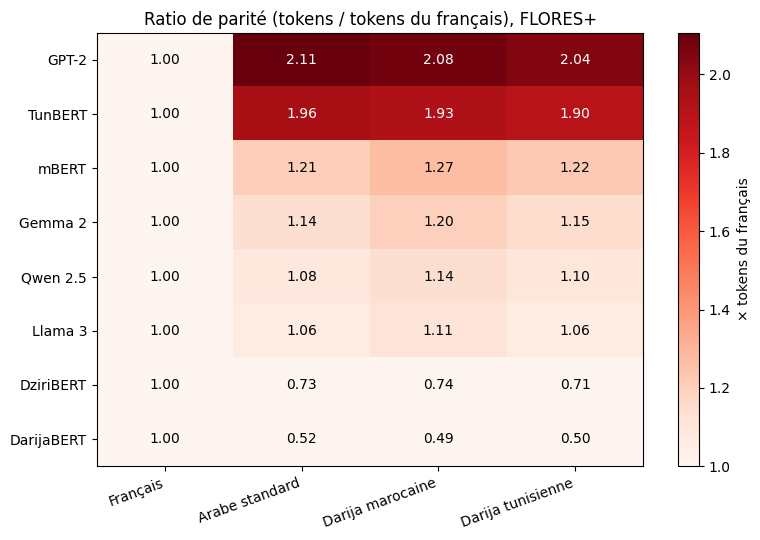

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 0.5 * len(parite) + 1.5))
im = ax.imshow(parite.values, cmap="Reds", vmin=1, aspect="auto")
ax.set_xticks(range(parite.shape[1]), parite.columns, rotation=20, ha="right")
ax.set_yticks(range(parite.shape[0]), parite.index)
for i in range(parite.shape[0]):
    for j in range(parite.shape[1]):
        v = parite.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > parite.values.max() * 0.7 else "black")
ax.set_title("Ratio de parité (tokens / tokens du français), FLORES+")
fig.colorbar(im, ax=ax, label="× tokens du français")
fig.tight_layout()
fig.savefig("results/figures/exp1_parite_flores.png", dpi=200)
plt.show()

## 5. Voir le découpage : une phrase, plusieurs tokenizers

Chaque couleur = un token. Un **�** signale une lettre coupée en octets : le tokenizer ne la connaît pas comme un tout.

C'est cette visualisation qui servira d'ouverture à l'oral.

In [10]:
from IPython.display import HTML, display

COLORS = ["#fde2e4", "#e2ece9", "#dfe7fd", "#fff1c1", "#e8dff5", "#d7f2f5"]

def show_tokens(text, names=None):
    names = names or list(tokenizers)
    rtl = any("\u0600" <= c <= "\u06FF" for c in text)
    html = []
    for name in names:
        tok = tokenizers[name]
        ids = tok.encode(text, add_special_tokens=False)
        spans = "".join(
            f'<span style="background:{COLORS[k % len(COLORS)]};padding:2px 1px;margin:0 1px;border-radius:3px">'
            f'{tok.decode([i]).replace(" ", "&nbsp;")}</span>'
            for k, i in enumerate(ids)
        )
        html.append(
            f'<tr><td style="padding:4px 12px 4px 0;white-space:nowrap"><b>{name}</b><br>{len(ids)} tokens</td>'
            f'<td dir="{"rtl" if rtl else "ltr"}" style="font-size:18px;line-height:2">{spans}</td></tr>'
        )
    display(HTML(f"<table>{''.join(html)}</table>"))

i = 0  # changez l'indice pour voir d'autres phrases
for lang in ["Français", "Darija marocaine"]:
    print(f"--- {lang}")
    show_tokens(data[lang].iloc[i])

--- Français


GPT-2131 tokens
Llama 398 tokens
Qwen 2.595 tokens
Gemma 287 tokens
mBERT96 tokens
DziriBERT102 tokens
DarijaBERT150 tokens
TunBERT116 tokens


--- Darija marocaine


GPT-2206 tokens
Llama 383 tokens
Qwen 2.583 tokens
Gemma 274 tokens
mBERT79 tokens
DziriBERT55 tokens
DarijaBERT55 tokens
TunBERT168 tokens


## 6. À noter dans `results/journal.md`

La cellule suivante prépare les lignes à copier dans le journal des résultats.

In [11]:
import datetime, subprocess

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
today = datetime.date.today().isoformat()
for tok_name in parite.index:
    for lang in ["Darija marocaine", "Darija tunisienne"]:
        print(f"| {today} | 1 | {tok_name}, FLORES+, normalise={NORMALIZE} | parité vs fr ({lang}) | {parite.loc[tok_name, lang]:.2f} | — | {commit} | Ammar |")

| 2026-11-18 | 1 | GPT-2, FLORES+, normalise=True | parité vs fr (Darija marocaine) | 2.08 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | GPT-2, FLORES+, normalise=True | parité vs fr (Darija tunisienne) | 2.04 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | TunBERT, FLORES+, normalise=True | parité vs fr (Darija marocaine) | 1.93 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | TunBERT, FLORES+, normalise=True | parité vs fr (Darija tunisienne) | 1.90 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | mBERT, FLORES+, normalise=True | parité vs fr (Darija marocaine) | 1.27 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | mBERT, FLORES+, normalise=True | parité vs fr (Darija tunisienne) | 1.22 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | Gemma 2, FLORES+, normalise=True | parité vs fr (Darija marocaine) | 1.20 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | Gemma 2, FLORES+, normalise=True | parité vs fr (Darija tunisienne) | 1.15 | — | 408cd4d | Ammar |
| 2026-11-18 | 1 | Qwen 2.5, FLORES+, normalise=True | parité vs fr 

## 7. Suite

- [ ] Confirmer les identifiants marqués « à vérifier » et relancer.
- [ ] Ajouter **MADAR** dès que l'accès est obtenu : c'est la seule source avec l'**algérien**.
- [ ] Bonus **arabizi** : faire transcrire 50 phrases en arabizi par des natifs et comparer avec l'alphabet arabe.
- [ ] Lire les premiers résultats : quel tokenizer pénalise le plus la darija ? L'arabe standard est-il mieux traité que la darija ?